# CAP182 SS3 — Part B: Applying the XGBoost Return-Prediction Method to STADIOalot Data

**Objective:** apply the XGBoost classifier selected in SS2 to the new STADIOalot order data and evaluate its performance on later, unseen orders.

This notebook uses `return_status` (`Returned` / `Not Returned`) as the target. The main evaluation is chronological so that the test set represents later orders than the training set. The workflow intentionally excludes post-return information to avoid target leakage.

> Run this notebook from the directory containing the six supplied CSV files, or update `DATA_DIR` below. XGBoost must be installed (`pip install xgboost`).

## 1. Dataset loading

Six supplied CSV tables are loaded and their dimensions inspected. The prediction target is order-level `return_status` (`Returned` / `Not Returned`). The transaction table has multiple product lines for some orders, so these lines are aggregated to one order-level modelling record in preprocessing. Class counts and return prevalence are reported from the actual target data.

The clickstream table has `user_id` but no `order_id`. It is not joined because a direct user-level merge could create many-to-many rows and could mix sessions that occurred after an order.


In [18]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.model_selection import train_test_split

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("Install XGBoost first: pip install xgboost") from exc

RANDOM_STATE = 42
# Use ./data when running from the package root; fall back to the notebook directory.
DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path(".")


FILES = {
    "orders": "table1_orders_transactions.csv",
    "products": "table2_product_seller.csv",
    "customers": "table3_customer.csv",
    "clickstream": "table4_clickstream.csv",
    "returns": "table5_returns.csv",
    "finance": "table6_financial_sustainability.csv",
}

tables = {name: pd.read_csv(DATA_DIR / filename) for name, filename in FILES.items()}
for name, frame in tables.items():
    print(f"{name:12s}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")

target_counts = tables["returns"]["return_status"].astype("string").str.strip().str.title().value_counts(dropna=False)
display(target_counts.to_frame("orders"))
print(f"Target records in returns table: {len(tables['returns']):,}")
print(f"Returned share: {(target_counts.get('Returned', 0) / target_counts.sum()):.1%}")

orders      : 12,896 rows × 12 columns
products    : 1,487 rows × 12 columns
customers   : 12,871 rows × 11 columns
clickstream : 12,871 rows × 13 columns
returns     : 12,871 rows × 10 columns
finance     : 12,871 rows × 11 columns


,orders
return_status,
Not Returned,10197
Returned,2674


Target records in returns table: 12,871
Returned share: 20.8%


## 2. Dataset preprocessing and feature construction

The target is defined at order level, so all transaction lines are aggregated by `order_id`; no order is represented by an arbitrary first product line. Order-time numeric features are summarised (totals, means, line count, distinct products/categories/sellers), and categorical order/product attributes use a deterministic mode. Customer attributes are joined one-to-one by order ID.

Text whitespace is normalised, exact duplicates are removed, and source keys are deduplicated only where the table is expected to be one row per key. Order dates are parsed and records without a usable date or target are excluded. Post-return variables—including return reason/date, refund, return condition/method/processing, and return-related financial outcomes—are not predictors.

A chronological 70%/15%/15% split is used to approximate future deployment. Imputation and one-hot encoding are fitted only on training data inside a pipeline. Numeric missing values use the training median; categorical missing values use the training most-frequent value; unseen categories are ignored safely by the encoder.


In [19]:
# Normalise string fields and validate the target.
orders = tables["orders"].copy()
products = tables["products"].copy()
customers = tables["customers"].copy()
returns = tables["returns"].copy()

for frame in (orders, products, customers, returns):
    for col in frame.select_dtypes(include=["object", "string"]).columns:
        frame[col] = frame[col].astype("string").str.strip()

returns["return_status"] = returns["return_status"].str.title()
returns = returns[returns["return_status"].isin(["Returned", "Not Returned"])].copy()

# Remove exact duplicate source rows, then enforce the expected keys.
orders = orders.drop_duplicates()
products = products.drop_duplicates()
customers = customers.drop_duplicates(subset=["order_id"], keep="first")
returns = returns.drop_duplicates(subset=["order_id"], keep="first")
products = products.drop_duplicates(subset=["product_id"], keep="first")

# Enrich each order line with product-master attributes before aggregating to order level.
products = products.rename(columns={"product_category": "master_product_category"})
product_features = [
    "product_id", "seller_id", "master_product_category", "product_brand",
    "product_size", "product_colour", "size_colour_combination",
    "product_rating", "review_count", "product_age_days",
    "product_availability", "seller_return_rate"
]
line_data = orders.merge(products[product_features], on="product_id", how="left", validate="many_to_one")

# The prediction target is order-level. Aggregate all lines belonging to each order rather
# than retaining an arbitrary first line. Numeric totals/means and categorical modes are
# computed using only order-time and product-master attributes.
def first_non_null(series):
    s = series.dropna()
    return s.iloc[0] if len(s) else np.nan

def mode_or_first(series):
    s = series.dropna()
    if s.empty:
        return np.nan
    modes = s.mode()
    return modes.iloc[0] if not modes.empty else s.iloc[0]

agg = {
    "user_id": ("user_id", first_non_null),
    "order_date": ("order_date", first_non_null),
    "order_line_count": ("product_id", "size"),
    "distinct_products": ("product_id", "nunique"),
    "product_price_sum": ("product_price", "sum"),
    "product_price_mean": ("product_price", "mean"),
    "order_quantity_sum": ("order_quantity", "sum"),
    "discount_sum": ("discount_applied", "sum"),
    "order_value_sum": ("order_value", "sum"),
    "delivery_distance_km": ("delivery_distance_km", "mean"),
    "product_category": ("product_category", mode_or_first),
    "shipping_method": ("shipping_method", mode_or_first),
    "payment_method": ("payment_method", mode_or_first),
    "master_product_category": ("master_product_category", mode_or_first),
    "product_brand": ("product_brand", mode_or_first),
    "product_size": ("product_size", mode_or_first),
    "product_colour": ("product_colour", mode_or_first),
    "size_colour_combination": ("size_colour_combination", mode_or_first),
    "product_rating_mean": ("product_rating", "mean"),
    "review_count_mean": ("review_count", "mean"),
    "product_age_days_mean": ("product_age_days", "mean"),
    "product_availability": ("product_availability", mode_or_first),
    "seller_return_rate_mean": ("seller_return_rate", "mean"),
    "distinct_categories": ("product_category", "nunique"),
    "distinct_sellers": ("seller_id", "nunique"),
}
order_features = line_data.groupby("order_id", as_index=False).agg(**agg)

customer_features = [
    "order_id", "user_age", "user_gender", "user_location",
    "customer_tenure_months", "previous_orders", "previous_returns",
    "previous_return_rate", "average_order_value", "average_order_quantity"
]
data = order_features.merge(customers[customer_features], on="order_id", how="left", validate="one_to_one")
data = data.merge(returns[["order_id", "return_status"]], on="order_id", how="inner", validate="one_to_one")

data["order_date"] = pd.to_datetime(data["order_date"], errors="coerce")
data = data.dropna(subset=["order_date", "return_status"]).sort_values(["order_date", "order_id"]).reset_index(drop=True)

data["order_month"] = data["order_date"].dt.month
data["order_dayofweek"] = data["order_date"].dt.dayofweek
data["order_year"] = data["order_date"].dt.year
data["target"] = (data["return_status"] == "Returned").astype(int)

excluded = {"order_id", "user_id", "order_date", "return_status", "target"}
feature_cols = [c for c in data.columns if c not in excluded]
X = data[feature_cols].copy()
y = data["target"].copy()

print("Order-line records after exact duplicate removal:", len(orders))
print("Distinct orders in transaction table:", orders["order_id"].nunique())
print("Product rows:", len(products), "| unique product IDs:", products["product_id"].nunique())
print("Customer rows:", len(customers), "| unique order IDs:", customers["order_id"].nunique())
print("Valid target rows:", len(returns), "| unique order IDs:", returns["order_id"].nunique())
print("Model-ready order-level rows:", len(data))
print("Feature count:", len(feature_cols))
print("Class counts (0=Not Returned, 1=Returned):")
display(y.value_counts().sort_index().rename(index={0:"Not Returned", 1:"Returned"}).to_frame("count"))
print("Class proportions:")
display(y.value_counts(normalize=True).sort_index().rename(index={0:"Not Returned", 1:"Returned"}).to_frame("proportion"))
print("Date range:", data["order_date"].min(), "to", data["order_date"].max())
print("Duplicate order IDs after aggregation:", int(data["order_id"].duplicated().sum()))
print("Unmatched target records not represented in model-ready data:", len(returns) - returns["order_id"].isin(data["order_id"]).sum())
print("Post-outcome return and financial fields are not joined as predictors.")


Order-line records after exact duplicate removal: 12871
Distinct orders in transaction table: 12871
Product rows: 1487 | unique product IDs: 1487
Customer rows: 12871 | unique order IDs: 12871
Valid target rows: 12871 | unique order IDs: 12871
Model-ready order-level rows: 12734
Feature count: 35
Class counts (0=Not Returned, 1=Returned):


,count
target,
Not Returned,10081
Returned,2653


Class proportions:


,proportion
target,
Not Returned,0.79166
Returned,0.20834


Date range: 2022-09-01 07:03:24 to 2026-08-30 18:21:42
Duplicate order IDs after aggregation: 0
Unmatched target records not represented in model-ready data: 137
Post-outcome return and financial fields are not joined as predictors.


### Chronological train / validation / test split

Rows are sorted by order timestamp and split into 70% training, 15% validation and 15% final test. This preserves time order rather than randomly mixing past and future observations. The validation subset supports model review and any threshold selection; the test subset is held back for a final, once-only evaluation. Split sizes, dates and return prevalence are printed below.


In [20]:
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end].copy(), y.iloc[:train_end].copy()
X_val, y_val = X.iloc[train_end:val_end].copy(), y.iloc[train_end:val_end].copy()
X_test, y_test = X.iloc[val_end:].copy(), y.iloc[val_end:].copy()

print(f"Train: {len(X_train):,} rows | {data['order_date'].iloc[0]} to {data['order_date'].iloc[train_end-1]}")
print(f"Validation: {len(X_val):,} rows | {data['order_date'].iloc[train_end]} to {data['order_date'].iloc[val_end-1]}")
print(f"Test: {len(X_test):,} rows | {data['order_date'].iloc[val_end]} to {data['order_date'].iloc[-1]}")
for label, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{label} return rate: {yy.mean():.3f} (n={len(yy)})")

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop")

Train: 8,913 rows | 2022-09-01 07:03:24 to 2025-06-14 14:32:20
Validation: 1,910 rows | 2025-06-14 17:47:24 to 2026-01-25 14:31:05
Test: 1,911 rows | 2026-01-25 21:19:07 to 2026-08-30 18:21:42
Train return rate: 0.207 (n=8913)
Validation return rate: 0.201 (n=1910)
Test return rate: 0.224 (n=1911)


## 3. Model training — XGBoost

The selected method follows SS2: XGBoost, a gradient-boosted tree classifier suitable for structured data and nonlinear feature interactions. The baseline settings retain `n_estimators=150`, `max_depth=5`, `learning_rate=0.05`, `subsample=0.8`, and `colsample_bytree=0.8`. A modest learning rate and subsampling regularise learning; the tree depth controls interaction complexity. `scale_pos_weight` is computed from training labels only to address the minority Returned class without using validation or test outcomes. These are carried-forward baseline settings, not claimed to be globally optimal.


In [21]:
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / max(positive_count, 1)

xgb = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb)
])

model.fit(X_train, y_train)
print("Training completed.")
print("Training rows:", len(X_train))
print("scale_pos_weight (training-only):", round(scale_pos_weight, 3))

Training completed.
Training rows: 8913
scale_pos_weight (training-only): 3.839


## 4. Model validation

Evaluate the trained pipeline on the chronological validation subset using accuracy, precision, recall, F1 and ROC-AUC. Since Returned is the minority class, precision and recall for Returned are reported explicitly. The default probability threshold is 0.50 for this baseline. If a threshold is later selected to reflect the SS2 cost assumptions, it must be selected using validation data only and evaluated once on the untouched test set.


In [22]:
def evaluate_split(fitted_model, X_part, y_part, split_name, threshold=0.50):
    probabilities = fitted_model.predict_proba(X_part)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    print(f"\n--- {split_name} metrics (threshold={threshold:.2f}) ---")
    print(f"Accuracy:  {accuracy_score(y_part, predictions):.4f}")
    print(f"Precision (Returned): {precision_score(y_part, predictions, zero_division=0):.4f}")
    print(f"Recall (Returned):    {recall_score(y_part, predictions, zero_division=0):.4f}")
    print(f"F1 (Returned):        {f1_score(y_part, predictions, zero_division=0):.4f}")
    if y_part.nunique() == 2:
        print(f"ROC-AUC: {roc_auc_score(y_part, probabilities):.4f}")
    print(classification_report(y_part, predictions, target_names=["Not Returned", "Returned"], zero_division=0))
    return probabilities, predictions

val_prob, val_pred = evaluate_split(model, X_val, y_val, "Validation")


--- Validation metrics (threshold=0.50) ---
Accuracy:  0.7319
Precision (Returned): 0.3920
Recall (Returned):    0.6110
F1 (Returned):        0.4776
ROC-AUC: 0.7514
              precision    recall  f1-score   support

Not Returned       0.89      0.76      0.82      1527
    Returned       0.39      0.61      0.48       383

    accuracy                           0.73      1910
   macro avg       0.64      0.69      0.65      1910
weighted avg       0.79      0.73      0.75      1910



## 5. Final evaluation on unseen test data

The final test subset contains later-dated orders and is not used to fit the model or choose preprocessing parameters. Report its metrics as the final held-out estimate for this experiment. Because this dataset is synthetic and order-line aggregation changes the modelling unit to one record per order, these metrics should not be interpreted as production performance on real client data.



--- Unseen test metrics (threshold=0.50) ---
Accuracy:  0.7143
Precision (Returned): 0.4072
Recall (Returned):    0.6051
F1 (Returned):        0.4868
ROC-AUC: 0.7315
              precision    recall  f1-score   support

Not Returned       0.87      0.75      0.80      1483
    Returned       0.41      0.61      0.49       428

    accuracy                           0.71      1911
   macro avg       0.64      0.68      0.64      1911
weighted avg       0.76      0.71      0.73      1911



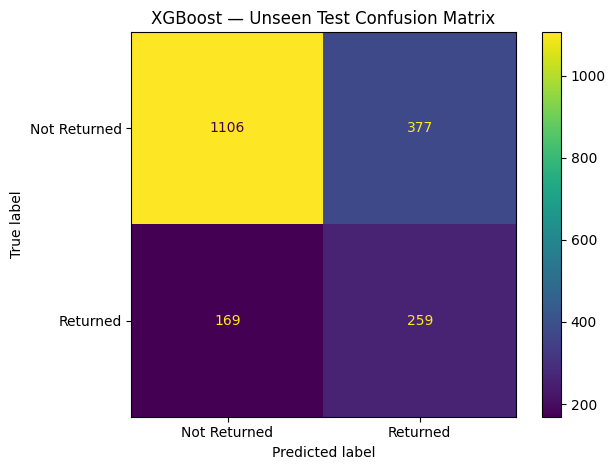

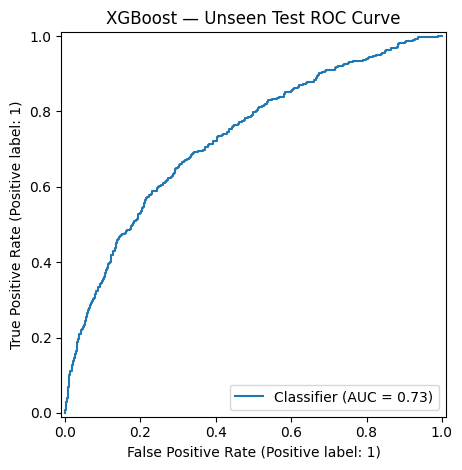

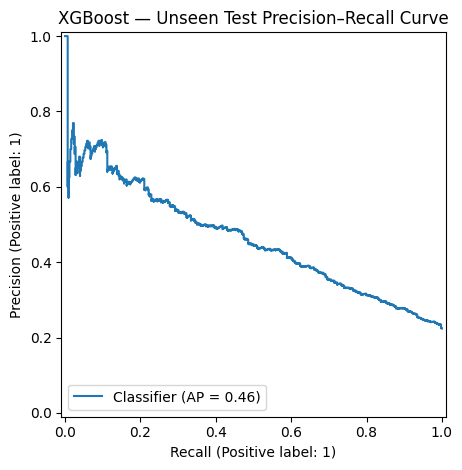

In [23]:
test_prob, test_pred = evaluate_split(model, X_test, y_test, "Unseen test")

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Returned", "Returned"])
disp.plot(values_format="d")
plt.title("XGBoost — Unseen Test Confusion Matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title("XGBoost — Unseen Test ROC Curve")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, test_prob)
plt.title("XGBoost — Unseen Test Precision–Recall Curve")
plt.tight_layout()
plt.show()

## 6. Results visualisation and interpretation

The charts below show return prevalence across chronological splits, held-out confusion matrix, ROC and precision–recall curves, and the most influential model features. Interpret feature importance as model reliance, not causal impact. Use the held-out results to describe the current baseline; use validation data for any future model/threshold selection.


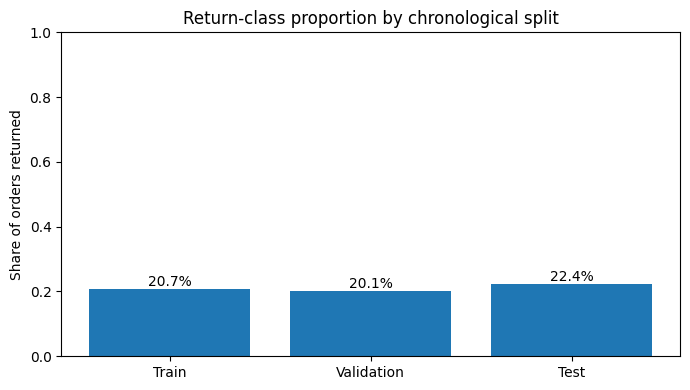

,Test score
Accuracy,0.714
Precision (Returned),0.407
Recall (Returned),0.605
F1 (Returned),0.487
ROC-AUC,0.732


,Importance
categorical__master_product_category_Footwear,0.062451
categorical__product_size_One Size,0.057241
categorical__master_product_category_Apparel,0.033864
numeric__previous_returns,0.023077
numeric__previous_return_rate,0.017413
categorical__product_category_Footwear,0.015763
categorical__product_category_Baby & Kids,0.011582
categorical__product_category_Apparel,0.008769
categorical__size_colour_combination_XXL-Olive,0.008712
categorical__product_size_12,0.008267


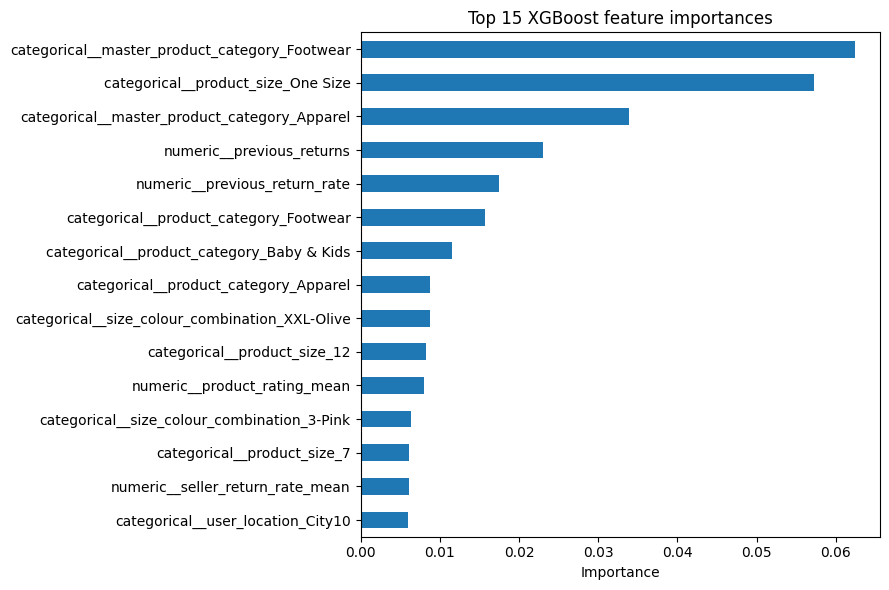

In [24]:
split_rates = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Return rate": [y_train.mean(), y_val.mean(), y_test.mean()]
})
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(split_rates["Split"], split_rates["Return rate"])
ax.set_ylim(0, 1)
ax.set_ylabel("Share of orders returned")
ax.set_title("Return-class proportion by chronological split")
ax.bar_label(bars, labels=[f"{v:.1%}" for v in split_rates["Return rate"]])
plt.tight_layout()
plt.show()

test_metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision (Returned)": precision_score(y_test, test_pred, zero_division=0),
    "Recall (Returned)": recall_score(y_test, test_pred, zero_division=0),
    "F1 (Returned)": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob) if y_test.nunique() == 2 else np.nan
}]).T.rename(columns={0:"Test score"})
display(test_metrics.style.format("{:.3f}"))

# Feature importance after preprocessing.
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]
try:
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = pd.Series(fitted_classifier.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
    display(importances.rename("Importance").to_frame())
    ax = importances.sort_values().plot(kind="barh", figsize=(9, 6))
    ax.set_title("Top 15 XGBoost feature importances")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Feature importance plot could not be generated:", exc)

## 7. Limitations and future steps


- The supplied dataset is synthetic; real-world generalisation must be tested with authorised operational data.
- The modelling unit is one order. Order-line features are aggregated to avoid dropping multi-product information.
- The clickstream table is excluded until a safe order/session linkage and temporal cutoff are available.
- Post-return fields are excluded to prevent target leakage.
- The 0.50 decision threshold is a baseline, not a cost-optimal threshold. Select any alternative using validation data and test it once.
- Evaluate calibration, threshold-dependent expected cost, fairness, and drift before operational deployment.
